In [6]:
# Import analysis libraries.
import pandas as pd
import numpy as np
import math
import scipy.stats as stats

# Import visualization libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Import engine connection file.
from _01_database_connection import engine

In [7]:
# Read the data.
fact_sales = pd.read_sql(
    sql="SELECT order_number, sales FROM gold.fact_sales",
    con=engine
)

# Pick a sample.
fact_sales.sample(5)

,order_number,sales
17416,SO56489,8
9572,SO53016,9
57889,SO74040,2295
52415,SO71683,35
8587,SO52601,54


### GRAIN: Each row represents an item within an order. ###

**Q1: What was the revenue percentage made by top 1%, 5%, 10%, 20% and 50% of the orders?**

In [8]:
# Group the data by the order_number to aggregate it by the order-level.
grouped_orders = fact_sales.groupby(
    by="order_number"
)["sales"].sum()

# Pick a sample.
grouped_orders.sample(5)

order_number
SO46688    2443
SO43798    3578
SO60385      22
SO62684     571
SO62077    2355
Name: sales, dtype: int64

In [9]:
# Calculate the total revenue.
total_revenue = grouped_orders.sum()

# Order the values descendingly.
grouped_orders_desc_order = grouped_orders.sort_values(ascending=False) 

# Percentage of the orders needed to be calculated.
percentages = [0.01, 0.05, 0.10, 0.15, 0.20, 0.50]

for p in percentages:
    # Calculate number of orders with a specific percent.
    num_of_orders = math.ceil(len(grouped_orders) * p)

    # Pick the orders from the peak performance orders.
    total_revenue_of_top_p_orders = grouped_orders_desc_order.head(num_of_orders).sum()
    percent_of_revenue = (total_revenue_of_top_p_orders / total_revenue) * 100

    # Show the result.
    print(f"Top {(p * 100):.0f}% orders achived {percent_of_revenue:.2f}% of the total revenue.")

Top 1% orders achived 3.38% of the total revenue.
Top 5% orders achived 16.88% of the total revenue.
Top 10% orders achived 30.40% of the total revenue.
Top 15% orders achived 41.86% of the total revenue.
Top 20% orders achived 53.08% of the total revenue.
Top 50% orders achived 95.22% of the total revenue.


### Interpretation

Revenue concentratio is moderate: the top 20% achived 53.08% of the revenue(Well below a classic 80/20 pattern), and the top 1% only achived 3.4%.
The bottom 50% of orders contribute under 5% of revenue.

**Q2: What is the percent of top-tire orders that represent 80% of the revenue (Pareto analysis)?**

In [26]:
grouped_orders_desc_cum  = (grouped_orders_desc_order.cumsum() / total_revenue) * 100

# Number of top orders represent 80% of the revenue.
num_of_orders_to_reach_80 = (grouped_orders_desc_cum >= 80).argmax() + 1

# Print the result.
print(f"""Top {num_of_orders_to_reach_80 / len(grouped_orders) * 100:.2f}% of orders represent 80% of the revenue!
and, the remaining {(len(grouped_orders_desc_cum) - num_of_orders_to_reach_80) / len(grouped_orders) * 100:.2f}% of orders generate only 20% of revenue!""")

Top 33.41% of orders represent 80% of the revenue!
and, the remaining 66.59% of orders generate only 20% of revenue!


**Q3: What is the shape of Cumulative Distribution Curve?**

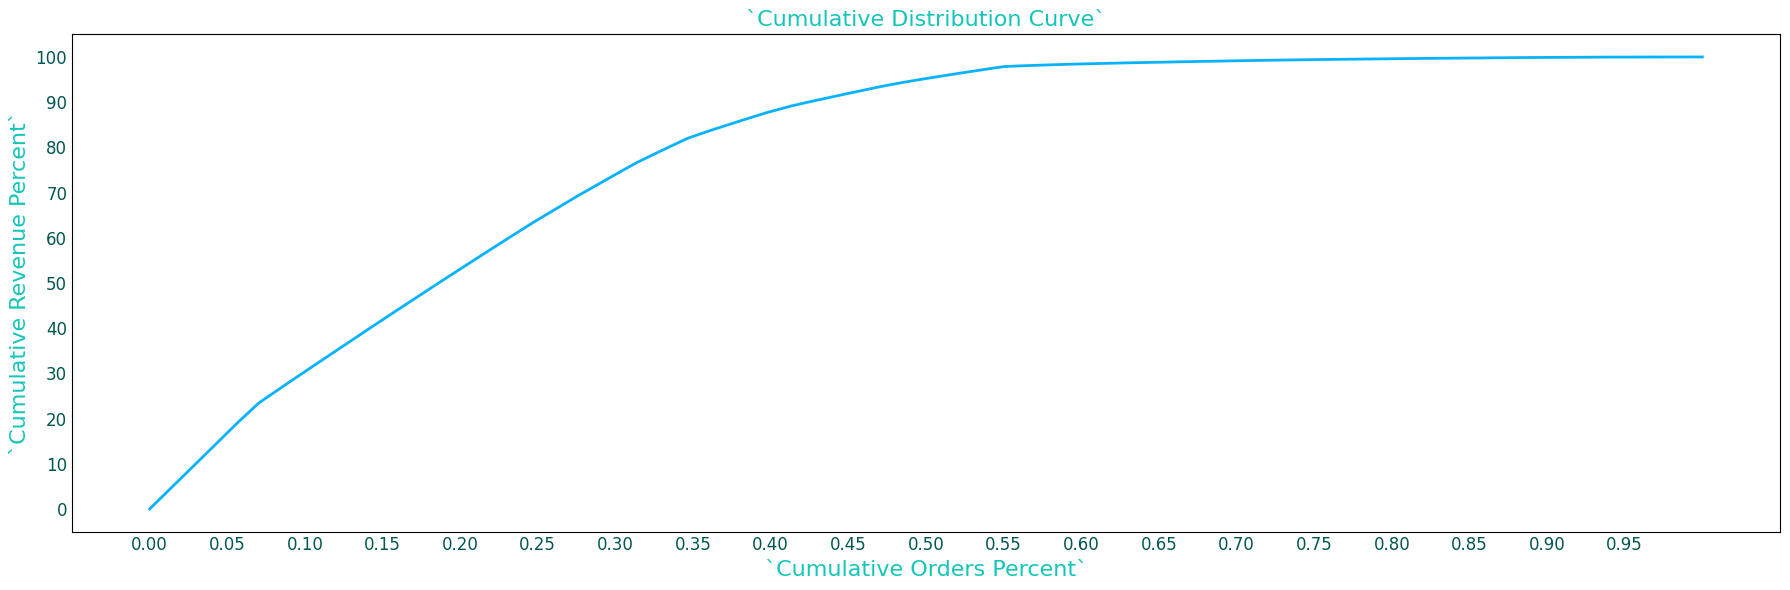

In [34]:
# Initialize the x and y axes.
x_axis = np.arange(1, len(grouped_orders) + 1) / len(grouped_orders)
y_axis = grouped_orders_desc_cum


fig, ax = plt.subplots(figsize=(18, 6))

sns.lineplot(
    x=x_axis,
    y=y_axis,
    ax=ax,
    color="#09B3FC",
    linewidth=2.0,
    alpha=1.0,
    );

# Set labels.
ax.set_title("`Cumulative Distribution Curve`", fontsize=16, color="#13C7B8");
ax.set_xlabel("`Cumulative Orders Percent`", fontsize=16, color="#13C7B8");
ax.set_ylabel("`Cumulative Revenue Percent`", fontsize=16, color="#13C7B8");
ax.set_xticks(np.arange(0, 1.0, 0.05));
ax.set_yticks(np.arange(0, 110, 10));
ax.tick_params("both", length=0, labelsize=12, labelcolor="#035750");

plt.tight_layout();

**Q4: What is the order value that 90% of orders values less than or equal?**

In [35]:
# The order value that 90% of orders values less than or equal.
result = np.percentile(grouped_orders, q=90) # 2451.0, 90% of the orders values less than or equal 2451.0
result

np.float64(2448.600000000002)

**Q5: What is the percent of orders their revenue <= 1000 $?**

**Q6: What is the percent of orders their revenue <= 1500 $?**

In [39]:
# Use ecdf (Empirical Cumulative Distribution Function).
ecdf = stats.ecdf(grouped_orders)

# Precent of orders their revenue <= 1000
pct_orders_less_or_equal_1000 = ecdf.cdf.evaluate(1000) * 100

# Precent of orders their revenue <= 1500
pct_orders_less_or_equal_1500 = ecdf.cdf.evaluate(1500) * 100


# Show the result.
print(f"Precent of orders their revenue <= 1000 is: {pct_orders_less_or_equal_1000:.2f}%")
print(f"Precent of orders their revenue <= 1500 is: {pct_orders_less_or_equal_1500:.2f}%")

Precent of orders their revenue <= 1000 is: 60.29%
Precent of orders their revenue <= 1500 is: 65.37%


**Q7: What is the shspe of (Empirical Cumulative Distribution Function)?**

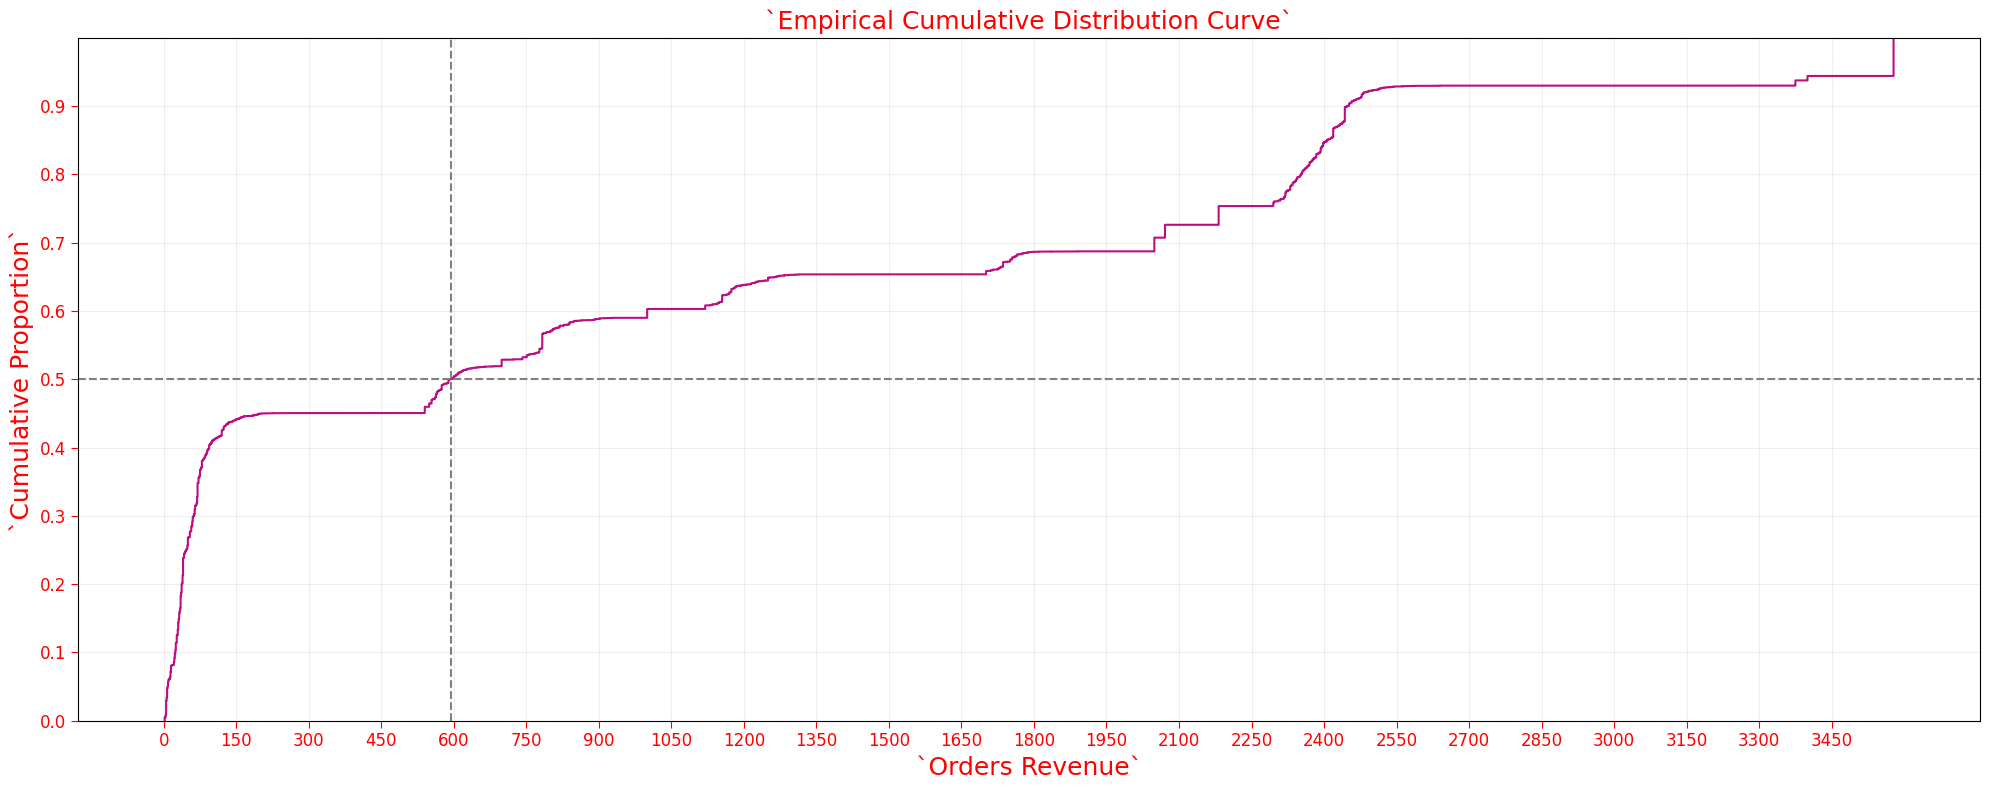

In [42]:
fig, ax = plt.subplots(figsize=(20, 8))

sns.ecdfplot(
    data=grouped_orders,
    ax=ax,
    color="#bd0d82"
);


# Label settings;
ax.set_title("`Empirical Cumulative Distribution Curve`", fontsize=18, color="r");
ax.set_ylabel("`Cumulative Proportion`", fontsize=18, color="r");
ax.set_xlabel("`Orders Revenue`", fontsize=18, color="r");
ax.set_xticks(np.arange(0, 3500, 150));
ax.set_yticks(np.arange(0, 1.0, 0.1));
ax.tick_params("both", labelsize=12, labelcolor="r", length=5, color="r");

# Show the median point.
ax.axhline(0.5, ls="--", c="gray");
ax.axvline(grouped_orders.median(), ls="--", c="gray");

# Set facecolor.
ax.set_facecolor("white");
ax.grid(True, alpha=0.2)

plt.tight_layout();

### Concolusion:

Statistical Revenue Concentration Analysis: Applied order-level aggregation, percentile analysis, Pareto behovior ECDF, and cumulative distribution analysis to quantify revenue concentration, assess order-value distribution, and identify the contribution of high-value orders to total revenue, supporting data-driven business insights.